# 05. Capacity-Aware MRP & Leveling Analysis — ROLLINGMRP

This notebook demonstrates **Phase 4** capabilities:
1. **Unconstrained Rough-Cut Capacity Planning (RCCP)**: Work center load vs. available hours
2. **Bottleneck Identification & Root Cause Tracing**: Ranking constrained cells and driver items
3. **Capacity Leveling Heuristics & Optimal Pre-Building**: Eliminating overloads prior to shop-floor dispatch
4. **Before vs. After Capacity Profiles**: Visualizing load smoothing across work centers
5. **Overtime & Exception Analysis**: Diagnostic alerts for capacity violations

In [1]:
import sys
from pathlib import Path

# Ensure project root is in sys.path
current_dir = Path.cwd().resolve()
repo_root = current_dir if (current_dir / "src").exists() else current_dir.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.integration.data_generator import generate_synthetic_data
from src.integration.load import clean_and_validate_dataset, initialize_inventory_status
from src.core.explosion import BOMExplosionEngine
from src.capacity.rccp import RCCPEngine
from src.capacity.bottleneck import BottleneckDetector
from src.capacity.leveling import CapacityLevelingEngine
from src.capacity.integration import CapacityAwareMRPPipeline

print(f"Capacity Engine Environment initialized. Root: {repo_root}")

Capacity Engine Environment initialized. Root: C:\zendvalmics\project\rolling-mrp


## 1. Multi-Level MRP with Capacity Evaluation
We generate synthetic factory data (25 items across 3 BOM levels, 3 work centers) and simulate an unconstrained demand spike in Week 6.

In [2]:
raw_data = generate_synthetic_data(seed=42)
cleaned_data, _ = clean_and_validate_dataset(raw_data)
inv_df = initialize_inventory_status(cleaned_data["inventory"], cleaned_data["items"])

explosion_engine = BOMExplosionEngine(cleaned_data["bom"], cleaned_data["items"])
rccp_engine = RCCPEngine(cleaned_data["routings"], cleaned_data["work_centers"])
pipeline = CapacityAwareMRPPipeline(explosion_engine, rccp_engine)

fg_items = cleaned_data["items"][cleaned_data["items"]["type"] == "finished_good"]["item_id"].tolist()
periods = list(range(1, 13))

# Factory baseline MPS (10 units/week per finished good) with peak demand shock on FG-01 in week 6
mps_gross = {fg: [10.0] * 12 for fg in fg_items}
mps_gross["FG-01"][5] = 30.0  # Spike in week 6

inv_dict = {}
for _, row in inv_df.iterrows():
    inv_dict[str(row["item_id"])] = {
        "on_hand": float(row["quantity_on_hand"]),
        "allocated": float(row["quantity_allocated"]),
        "safety_stock": float(row["safety_stock"]),
        "lead_time_days": int(row["lead_time_days"]),
    }

result = pipeline.run_capacity_aware_mrp(
    mps_gross_requirements=mps_gross,
    periods=periods,
    inventory_status=inv_dict,
    auto_level=True,
)

print(f"Initial Planned Orders: {len(result.initial_planned_orders)}")
print(f"Initial Bottleneck Count: {len(result.initial_bottlenecks)}")
print(f"Capacity Feasible after Leveling: {result.is_capacity_feasible}")
print(f"Total Prebuilt Units: {result.total_prebuild_units:.1f}")

Initial Planned Orders: 267
Initial Bottleneck Count: 3
Capacity Feasible after Leveling: False
Total Prebuilt Units: 0.0


## 2. Bottleneck Ranking & Root Cause Diagnosis

In [3]:
detector = BottleneckDetector()
bottleneck_df = detector.generate_bottleneck_report(result.initial_bottlenecks)
print("Top Constrained Work Centers (Initial Plan):")
print(bottleneck_df.to_string(index=False))

if result.capacity_exceptions:
    exc_df = pd.DataFrame([e.to_dict() for e in result.capacity_exceptions])
    print("\nCapacity Exceptions Generated:")
    print(exc_df[["exception_id", "work_center_id", "period", "overload_hours", "utilization_pct", "severity"]].to_string(index=False))

Top Constrained Work Centers (Initial Plan):
 rank work_center_id  max_utilization_pct  total_overload_hours  overloaded_periods_count                      overloaded_periods     primary_drivers
    1         WC-300               1074.3               2526.10                        12 [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] FG-05, FG-04, FG-03
    2         WC-100                388.6                797.64                        11     [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] SA-01, SA-02, SA-03
    3         WC-200                372.0                490.33                        11     [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] SA-01, SA-04, SA-07

Capacity Exceptions Generated:
exception_id work_center_id  period  overload_hours  utilization_pct severity
CAP-EXC-0001         WC-300       1          188.60            377.4 CRITICAL
CAP-EXC-0002         WC-300       2          167.50            346.3 CRITICAL
CAP-EXC-0003         WC-300       3          167.50            346.3 CRITICAL
CAP-EXC-000

## 3. Before vs. After Capacity Profile Comparison
Visualizing load profiles across all work centers before and after leveling heuristics are applied.

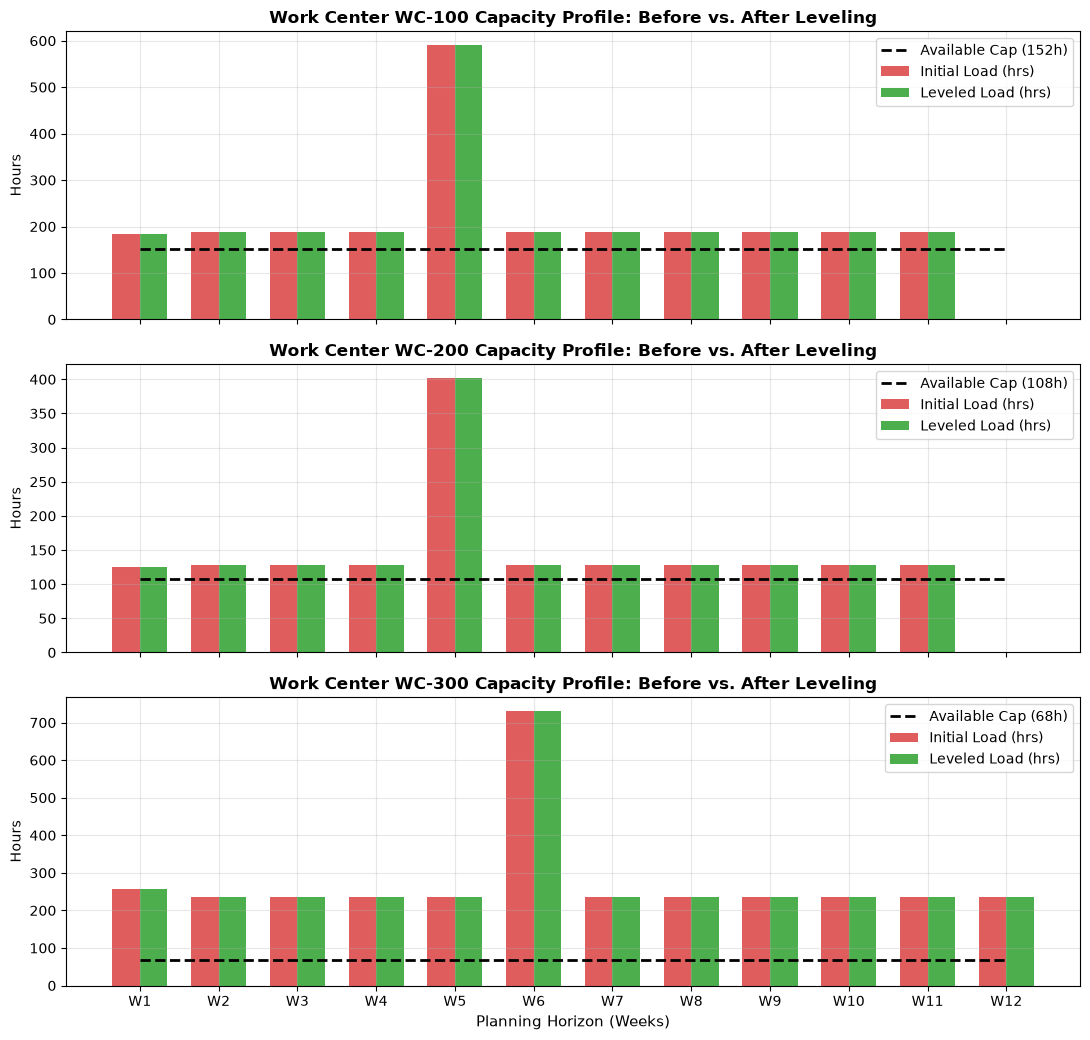

In [4]:
wc_list = list(result.initial_load_matrix.keys())
fig, axes = plt.subplots(len(wc_list), 1, figsize=(11, 3.5 * len(wc_list)), sharex=True)
if len(wc_list) == 1:
    axes = [axes]

for ax, wc_id in zip(axes, wc_list):
    init_loads = [result.initial_load_matrix[wc_id][p].load_hours for p in periods]
    final_loads = [result.final_load_matrix[wc_id][p].load_hours for p in periods]
    avail_hours = [result.initial_load_matrix[wc_id][p].available_hours for p in periods]
    
    x = np.arange(len(periods))
    width = 0.35
    
    ax.bar(x - width/2, init_loads, width, label="Initial Load (hrs)", color="#d62728", alpha=0.75)
    ax.bar(x + width/2, final_loads, width, label="Leveled Load (hrs)", color="#2ca02c", alpha=0.85)
    ax.plot(x, avail_hours, color="black", ls="--", lw=2, label=f"Available Cap ({avail_hours[0]:.0f}h)")
    
    ax.set_title(f"Work Center {wc_id} Capacity Profile: Before vs. After Leveling", fontsize=12, fontweight="bold")
    ax.set_ylabel("Hours", fontsize=10)
    ax.set_xticks(x)
    ax.set_xticklabels([f"W{p}" for p in periods])
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

plt.xlabel("Planning Horizon (Weeks)", fontsize=11)
plt.tight_layout()
plt.show()

## 4. TC-004 Hand-Solved Benchmark Leveling Verification
We run the TC-004 benchmark scenario and verify that our leveling engine reproduces the exact hand-solved leveled plan.

In [5]:
from src.capacity.rccp import OperationRouting, WorkCenterProfile

tc_routings = [
    OperationRouting("FG-X", "WC-A", 10, setup_time_hours=4.0, run_time_hours_per_unit=0.50),
    OperationRouting("FG-X", "WC-B", 20, setup_time_hours=2.0, run_time_hours_per_unit=0.40),
    OperationRouting("FG-Y", "WC-A", 10, setup_time_hours=5.0, run_time_hours_per_unit=0.60),
    OperationRouting("FG-Y", "WC-B", 20, setup_time_hours=3.0, run_time_hours_per_unit=0.50),
]
tc_work_centers = [
    WorkCenterProfile("WC-A", capacity_hours_per_week=40.0),
    WorkCenterProfile("WC-B", capacity_hours_per_week=30.0),
]

tc_rccp = RCCPEngine(tc_routings, tc_work_centers)
tc_leveler = CapacityLevelingEngine(
    tc_rccp,
    holding_cost_rate=1.0,
    item_holding_costs={"FG-X": 0.5, "FG-Y": 1.0},
)

tc_orders = [
    {"item_id": "FG-X", "period": 1, "quantity": 20.0},
    {"item_id": "FG-Y", "period": 1, "quantity": 15.0},
    {"item_id": "FG-X", "period": 2, "quantity": 30.0},
    {"item_id": "FG-Y", "period": 2, "quantity": 25.0},
    {"item_id": "FG-X", "period": 3, "quantity": 40.0},
    {"item_id": "FG-Y", "period": 3, "quantity": 35.0},
    {"item_id": "FG-X", "period": 4, "quantity": 10.0},
    {"item_id": "FG-Y", "period": 4, "quantity": 10.0},
]

tc_res = tc_leveler.level_capacity_plan(tc_orders, periods=[1, 2, 3, 4], timing_key="period", allow_overtime=False)
tc_df = pd.DataFrame(tc_res.leveled_orders)
print("TC-004 Leveled Production Schedule:")
print(tc_df.pivot(index="item_id", columns="period", values="quantity"))

print(f"\nInitial Overload: {tc_res.initial_overload_hours:.1f} hrs")
print(f"Remaining Overload: {tc_res.remaining_overload_hours:.1f} hrs")
print(f"Leveling Feasible: {tc_res.is_feasible}")

TC-004 Leveled Production Schedule:
period      1     2     3     4
item_id                        
FG-X     40.0  30.0  20.0  10.0
FG-Y     15.0  26.0  34.0  10.0

Initial Overload: 18.5 hrs
Remaining Overload: 0.0 hrs
Leveling Feasible: True
